# YouTube Trending Video Analytics


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Project Objective


In [ ]:
Analyze YouTube trending videos from India and USA to identify
popular categories, viewer engagement, title sentiment, and trending patterns.

## Tools Used

In [ ]:
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- TextBlob
- SQL
- Tableau

## 1.1 Verify Dataset File Path

Check whether the dataset file exists, is a valid file, and is readable.

In [2]:
import os

file_path = r"C:\Users\priya\Downloads\IN_youtube_trending_data.csv"

print("Path exists:", os.path.exists(file_path))
print("Is a file:", os.path.isfile(file_path))
print("Readable:", os.access(file_path, os.R_OK))

Path exists: True
Is a file: False
Readable: True


## 1. Load Dataset

In [3]:
import pandas as pd

file_path = r"C:\Users\priya\Downloads\IN_youtube_trending_data.csv"

df = pd.read_csv(file_path, nrows=10000)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (10000, 16)


,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description
0,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,2020-08-12T04:31:41Z,UCGqvJPRcv7aVFun-eTsatcA,FoxStarHindi,24,2020-08-12T00:00:00Z,sadak|sadak 2|mahesh bhatt|vishesh films|pooja...,9885899,224925,3979409,350210,https://i.ytimg.com/vi/Iot0eF6EoNA/default.jpg,False,False,Three Streams. Three Stories. One Journey. Sta...
1,x-KbnJ9fvJc,Kya Baat Aa : Karan Aujla (Official Video) Tan...,2020-08-11T09:00:11Z,UCm9SZAl03Rev9sFwloCdz1g,Rehaan Records,10,2020-08-12T00:00:00Z,[None],11308046,655450,33242,405146,https://i.ytimg.com/vi/x-KbnJ9fvJc/default.jpg,False,False,Singer/Lyrics: Karan Aujla Feat Tania Music/ D...
2,KX06ksuS6Xo,Diljit Dosanjh: CLASH (Official) Music Video |...,2020-08-11T07:30:02Z,UCZRdNleCgW-BGUJf-bbjzQg,Diljit Dosanjh,10,2020-08-12T00:00:00Z,clash diljit dosanjh|diljit dosanjh|diljit dos...,9140911,296533,6179,30058,https://i.ytimg.com/vi/KX06ksuS6Xo/default.jpg,False,False,CLASH official music video performed by DILJIT...
3,UsMRgnTcchY,Dil Ko Maine Di Kasam Video | Amaal M Ft.Ariji...,2020-08-10T05:30:49Z,UCq-Fj5jknLsUf-MWSy4_brA,T-Series,10,2020-08-12T00:00:00Z,hindi songs|2020 hindi songs|2020 new songs|t-...,23564512,743931,84162,136942,https://i.ytimg.com/vi/UsMRgnTcchY/default.jpg,False,False,Gulshan Kumar and T-Series presents Bhushan Ku...
4,WNSEXJJhKTU,"Baarish (Official Video) Payal Dev,Stebin Ben ...",2020-08-11T05:30:13Z,UCye6Oz0mg46S362LwARGVcA,VYRLOriginals,10,2020-08-12T00:00:00Z,VYRL Original|Mohsin Khan|Shivangi Joshi|Payal...,6783649,268817,8798,22984,https://i.ytimg.com/vi/WNSEXJJhKTU/default.jpg,False,False,VYRL Originals brings to you ‘Baarish’ - the b...


## 3. Dataset Overview

Display the dataset size and list all the columns available in the YouTube Trending dataset.

In [7]:
## 3. Dataset Overview
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (10000, 16)

Column names:
['video_id', 'title', 'publishedAt', 'channelId', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'description']


## 3.1 Dataset Information

Display the data types, number of non-null values, and memory usage of the dataset.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   video_id           10000 non-null  object
 1   title              10000 non-null  object
 2   publishedAt        10000 non-null  object
 3   channelId          10000 non-null  object
 4   channelTitle       10000 non-null  object
 5   categoryId         10000 non-null  int64 
 6   trending_date      10000 non-null  object
 7   tags               10000 non-null  object
 8   view_count         10000 non-null  int64 
 9   likes              10000 non-null  int64 
 10  dislikes           10000 non-null  int64 
 11  comment_count      10000 non-null  int64 
 12  thumbnail_link     10000 non-null  object
 13  comments_disabled  10000 non-null  bool  
 14  ratings_disabled   10000 non-null  bool  
 15  description        9913 non-null   object
dtypes: bool(2), int64(5), object(9)
memory us

## 3.2 Check Missing Values

Check the number of missing values in each column of the dataset.

In [22]:
df.isnull().sum()

video_id              0
title                 0
publishedAt           0
channelId             0
channelTitle          0
categoryId            0
trending_date         0
tags                  0
view_count            0
likes                 0
dislikes              0
comment_count         0
thumbnail_link        0
comments_disabled     0
ratings_disabled      0
description          87
dtype: int64

## 4. Data Cleaning and Preprocessing

Clean the dataset by removing duplicate rows, converting date columns, handling missing values, and removing rows with missing important fields.

In [23]:
# Make a copy for cleaning
df_clean = df.copy()

# 1. Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Convert date columns to datetime
df_clean['publishedAt'] = pd.to_datetime(
    df_clean['publishedAt'],
    errors='coerce'
)

df_clean['trending_date'] = pd.to_datetime(
    df_clean['trending_date'],
    errors='coerce'
)

# 3. Handle missing descriptions
df_clean['description'] = df_clean['description'].fillna('No description')

# 4. Handle missing tags
df_clean['tags'] = df_clean['tags'].fillna('No tags')

# 5. Remove rows where important fields are missing
df_clean = df_clean.dropna(
    subset=['video_id', 'title', 'view_count', 'likes', 'comment_count']
)

# 6. Reset index
df_clean = df_clean.reset_index(drop=True)

print("Cleaning completed!")
print("Rows and columns:", df_clean.shape)

Cleaning completed!
Rows and columns: (9996, 16)


## 4. Data Cleaning and Preprocessing

Clean the original dataset by removing duplicate rows, converting date columns to datetime format, handling missing text values, and removing rows with missing important information.

The cleaning results are also checked using missing-value counts, duplicate counts, data types, and the first five cleaned records.

## 4. Data Cleaning and Preprocessing

Clean the original dataset by removing duplicate rows, converting date columns to datetime format, handling missing text values, and removing rows with missing important information.

The cleaning results are checked using missing values, duplicate rows, data types, and the first five cleaned records.

In [9]:
# STEP 8: DATA CLEANING

# Create a copy of the original dataset
df_clean = df.copy()

# 1. Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Convert date columns to datetime format
df_clean['publishedAt'] = pd.to_datetime(
    df_clean['publishedAt'],
    errors='coerce'
)

df_clean['trending_date'] = pd.to_datetime(
    df_clean['trending_date'],
    errors='coerce'
)

# 3. Fill missing text values
df_clean['description'] = df_clean['description'].fillna('No description')
df_clean['tags'] = df_clean['tags'].fillna('No tags')

# 4. Remove rows missing important information
df_clean = df_clean.dropna(
    subset=[
        'video_id',
        'title',
        'view_count',
        'likes',
        'comment_count'
    ]
)

# 5. Reset the index
df_clean = df_clean.reset_index(drop=True)

# 6. Display cleaning results
print("========== DATA CLEANING RESULTS ==========")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Number of columns:", len(df_clean.columns))

print("\n========== MISSING VALUES ==========")
print(df_clean.isnull().sum())

print("\n========== DUPLICATE ROWS ==========")
print("Duplicate rows:", df_clean.duplicated().sum())

print("\n========== DATA TYPES ==========")
print(df_clean.dtypes)

print("\n========== FIRST 5 CLEANED ROWS ==========")
display(df_clean.head())

========== DATA CLEANING RESULTS ==========
Original rows: 10000
Cleaned rows: 9996
Rows removed: 4
Number of columns: 16

========== MISSING VALUES ==========
video_id             0
title                0
publishedAt          0
channelId            0
channelTitle         0
categoryId           0
trending_date        0
tags                 0
view_count           0
likes                0
dislikes             0
comment_count        0
thumbnail_link       0
comments_disabled    0
ratings_disabled     0
description          0
dtype: int64

========== DUPLICATE ROWS ==========
Duplicate rows: 0

========== DATA TYPES ==========
video_id                          object
title                             object
publishedAt          datetime64[ns, UTC]
channelId                         object
channelTitle                      object
categoryId                         int64
trending_date        datetime64[ns, UTC]
tags                              object
view_count                         int64


,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description
0,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,2020-08-12 04:31:41+00:00,UCGqvJPRcv7aVFun-eTsatcA,FoxStarHindi,24,2020-08-12 00:00:00+00:00,sadak|sadak 2|mahesh bhatt|vishesh films|pooja...,9885899,224925,3979409,350210,https://i.ytimg.com/vi/Iot0eF6EoNA/default.jpg,False,False,Three Streams. Three Stories. One Journey. Sta...
1,x-KbnJ9fvJc,Kya Baat Aa : Karan Aujla (Official Video) Tan...,2020-08-11 09:00:11+00:00,UCm9SZAl03Rev9sFwloCdz1g,Rehaan Records,10,2020-08-12 00:00:00+00:00,[None],11308046,655450,33242,405146,https://i.ytimg.com/vi/x-KbnJ9fvJc/default.jpg,False,False,Singer/Lyrics: Karan Aujla Feat Tania Music/ D...
2,KX06ksuS6Xo,Diljit Dosanjh: CLASH (Official) Music Video |...,2020-08-11 07:30:02+00:00,UCZRdNleCgW-BGUJf-bbjzQg,Diljit Dosanjh,10,2020-08-12 00:00:00+00:00,clash diljit dosanjh|diljit dosanjh|diljit dos...,9140911,296533,6179,30058,https://i.ytimg.com/vi/KX06ksuS6Xo/default.jpg,False,False,CLASH official music video performed by DILJIT...
3,UsMRgnTcchY,Dil Ko Maine Di Kasam Video | Amaal M Ft.Ariji...,2020-08-10 05:30:49+00:00,UCq-Fj5jknLsUf-MWSy4_brA,T-Series,10,2020-08-12 00:00:00+00:00,hindi songs|2020 hindi songs|2020 new songs|t-...,23564512,743931,84162,136942,https://i.ytimg.com/vi/UsMRgnTcchY/default.jpg,False,False,Gulshan Kumar and T-Series presents Bhushan Ku...
4,WNSEXJJhKTU,"Baarish (Official Video) Payal Dev,Stebin Ben ...",2020-08-11 05:30:13+00:00,UCye6Oz0mg46S362LwARGVcA,VYRLOriginals,10,2020-08-12 00:00:00+00:00,VYRL Original|Mohsin Khan|Shivangi Joshi|Payal...,6783649,268817,8798,22984,https://i.ytimg.com/vi/WNSEXJJhKTU/default.jpg,False,False,VYRL Originals brings to you ‘Baarish’ - the b...


## 5. Exploratory Data Analysis (EDA)

Explore the cleaned dataset to understand its main characteristics.

This analysis includes statistical summaries, total and average engagement, the most viewed videos, top channels by total views, and category distribution.

In [15]:
# ============================================
# STEP 9: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================

# 1. Basic statistical summary
print("========== STATISTICAL SUMMARY ==========")
display(df_clean[['view_count', 'likes', 'dislikes', 'comment_count']].describe())

# 2. Total engagement
total_views = df_clean['view_count'].sum()
total_likes = df_clean['likes'].sum()
total_dislikes = df_clean['dislikes'].sum()
total_comments = df_clean['comment_count'].sum()

print("\n========== TOTAL ENGAGEMENT ==========")
print("Total Views      :", f"{total_views:,}")
print("Total Likes      :", f"{total_likes:,}")
print("Total Dislikes   :", f"{total_dislikes:,}")
print("Total Comments   :", f"{total_comments:,}")

# 3. Average engagement
print("\n========== AVERAGE ENGAGEMENT ==========")
print("Average Views    :", f"{df_clean['view_count'].mean():,.2f}")
print("Average Likes    :", f"{df_clean['likes'].mean():,.2f}")
print("Average Dislikes :", f"{df_clean['dislikes'].mean():,.2f}")
print("Average Comments :", f"{df_clean['comment_count'].mean():,.2f}")

# 4. Most viewed videos
print("\n========== TOP 10 MOST VIEWED VIDEOS ==========")

top_videos = df_clean[
    ['video_id', 'title', 'channelTitle', 'view_count', 'likes', 'comment_count']
].sort_values(
    by='view_count',
    ascending=False
).head(10)

display(top_videos)

# 5. Top channels by total views
print("\n========== TOP 10 CHANNELS BY TOTAL VIEWS ==========")

top_channels = (
    df_clean.groupby('channelTitle')['view_count']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_channels)

# 6. Category distribution
print("\n========== CATEGORY DISTRIBUTION ==========")

category_counts = df_clean['categoryId'].value_counts().head(10)

display(category_counts)

========== STATISTICAL SUMMARY ==========


,view_count,likes,dislikes,comment_count
count,9.996000e+03,9.996000e+03,9.996000e+03,9.996000e+03
mean,2.665407e+06,1.457105e+05,2.114208e+04,2.464461e+04
std,8.942782e+06,6.428053e+05,3.589968e+05,2.202722e+05
min,1.677500e+04,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.865012e+05,1.164375e+04,5.430000e+02,6.887500e+02
50%,8.962880e+05,3.303800e+04,1.474500e+03,2.328000e+03
75%,2.125732e+06,9.695000e+04,4.052250e+03,7.079750e+03
max,2.539960e+08,1.611524e+07,1.234147e+07,6.249727e+06



========== TOTAL ENGAGEMENT ==========
Total Views      : 26,643,406,160
Total Likes      : 1,456,521,966
Total Dislikes   : 211,336,209
Total Comments   : 246,347,521

========== AVERAGE ENGAGEMENT ==========
Average Views    : 2,665,406.78
Average Likes    : 145,710.48
Average Dislikes : 21,142.08
Average Comments : 24,644.61

========== TOP 10 MOST VIEWED VIDEOS ==========


,video_id,title,channelTitle,view_count,likes,comment_count
3615,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,253995993,16115240,6249727
3367,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,244507902,15948359,6188781
3119,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,232649205,15735551,6064883
2889,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,219110491,15460834,5810606
2673,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,208581468,15246514,5744361
2468,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,200692965,14994040,5623663
4731,vRXZj0DzXIA,BLACKPINK - 'Ice Cream (with Selena Gomez)' M/V,BLACKPINK,184778248,11795683,2736021
2272,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,183414472,14678102,5748648
4494,vRXZj0DzXIA,BLACKPINK - 'Ice Cream (with Selena Gomez)' M/V,BLACKPINK,176467113,11645401,2722455
4259,vRXZj0DzXIA,BLACKPINK - 'Ice Cream (with Selena Gomez)' M/V,BLACKPINK,167334429,11474607,2710969



========== TOP 10 CHANNELS BY TOTAL VIEWS ==========


channelTitle
Big Hit Labels                   2677691540
BLACKPINK                        1630696123
T-Series                         1043401601
FoxStarHindi                      565900454
Geet MP3                          428640656
England & Wales Cricket Board     386709714
OPPO Mobile India                 385772215
Desi Music Factory                360161440
Diljit Dosanjh                    351816610
Google India                      289756242
Name: view_count, dtype: int64


========== CATEGORY DISTRIBUTION ==========


categoryId
24    3870
10    1888
23     936
22     876
28     496
26     473
25     472
17     392
27     184
20     137
Name: count, dtype: int64

## 6. Data Visualization

Create visualizations to identify important patterns in the YouTube Trending dataset.

The visualizations show:
- Top 10 YouTube channels by total views
- Top 10 categories by number of trending records
- Top 10 trending video records by views
- Relationship between views and likes

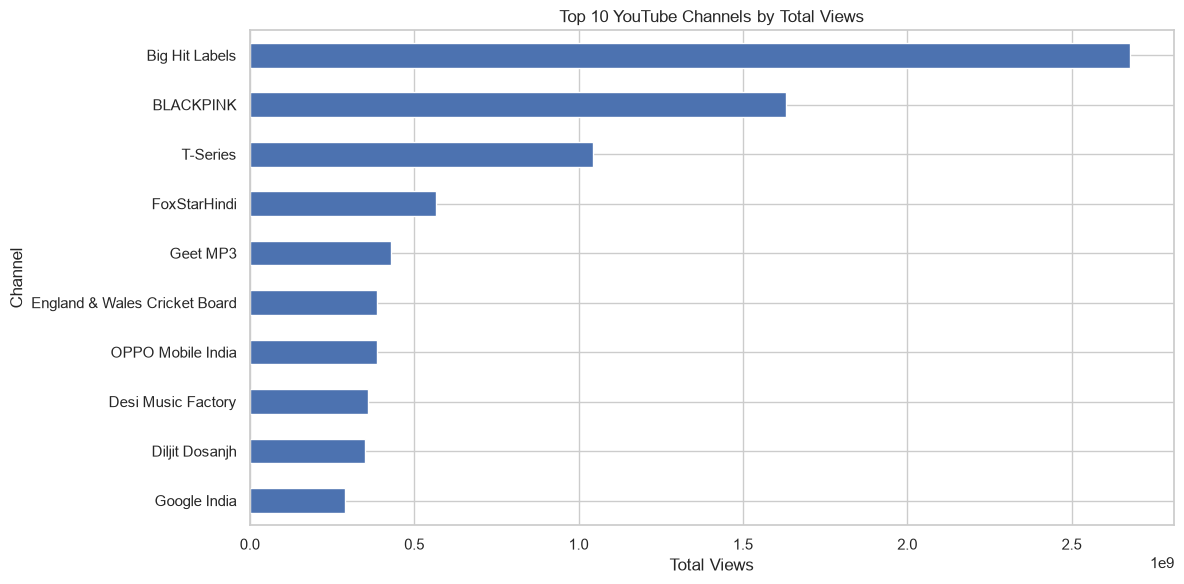

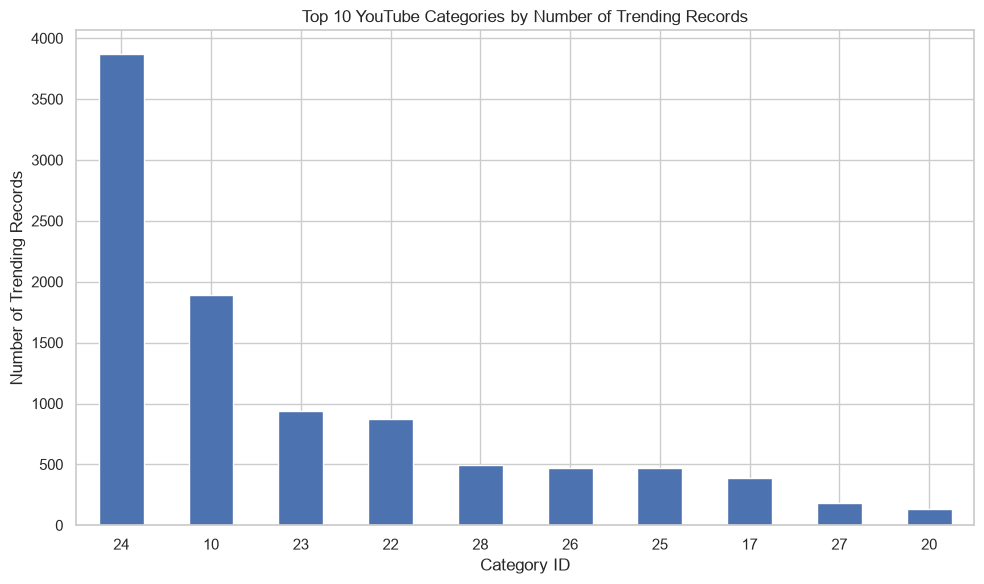

C:\Users\priya\AppData\Local\Temp\ipykernel_18580\695752059.py:84: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_18580\695752059.py:84: UserWarning: Glyph 53444 (\N{HANGUL SYLLABLE TAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_18580\695752059.py:84: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_18580\695752059.py:84: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_18580\695752059.py:84: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) Arial.
  fig.ca

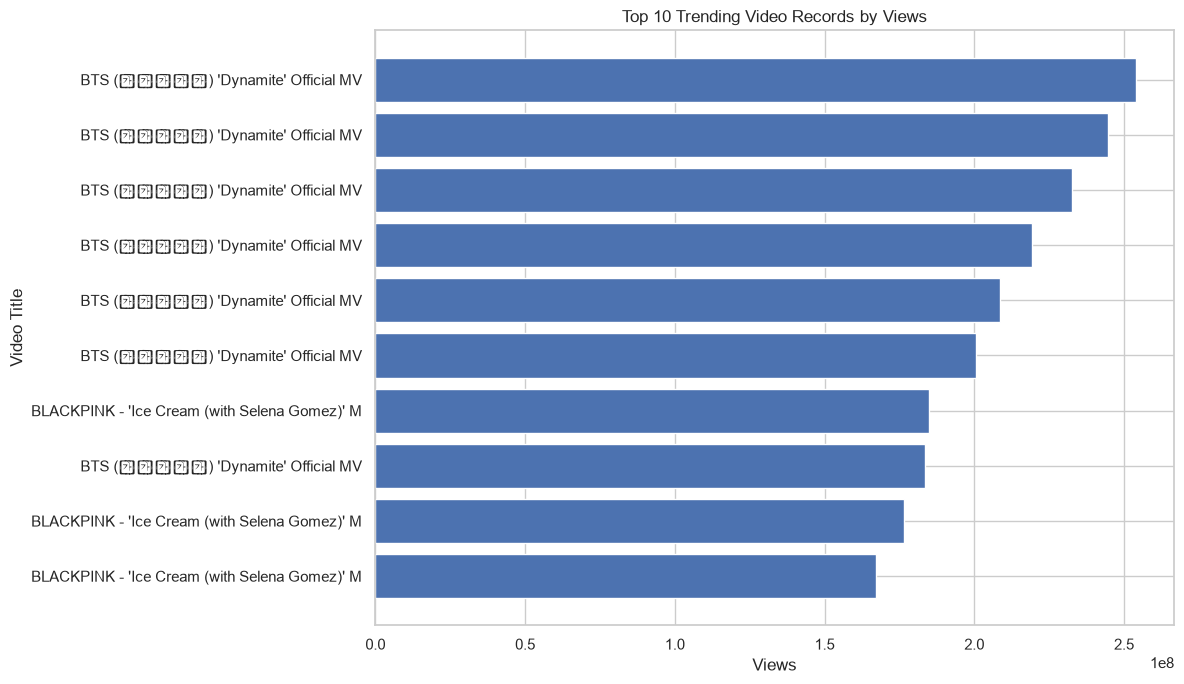

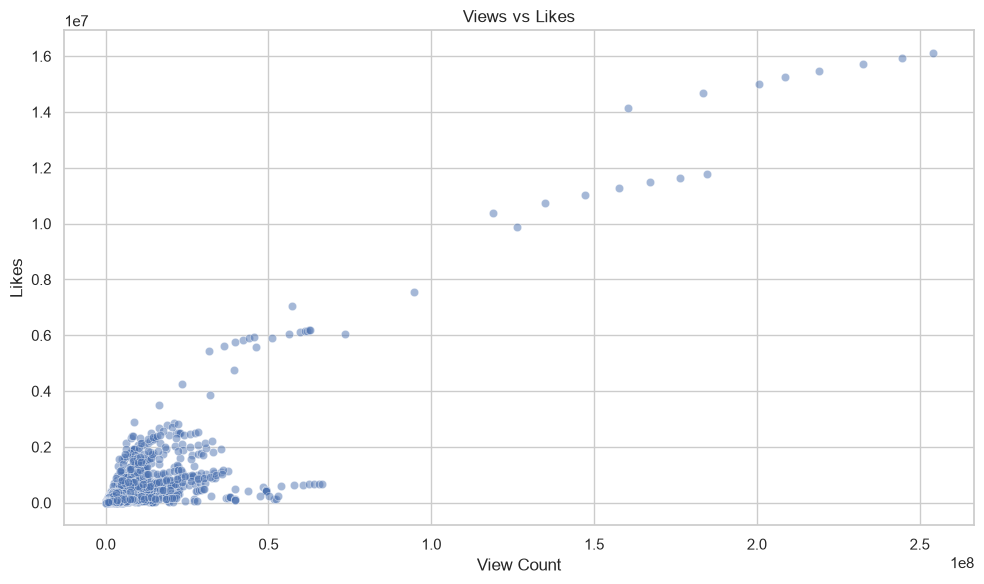

In [25]:
# ============================================
# STEP 10: DATA VISUALIZATION
# ============================================

# Set plotting style
sns.set_theme(style="whitegrid")


# ------------------------------------------------
# 1. TOP 10 CHANNELS BY TOTAL VIEWS
# ------------------------------------------------

top_channels = (
    df_clean.groupby('channelTitle')['view_count']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_channels.sort_values().plot(kind='barh')

plt.title('Top 10 YouTube Channels by Total Views')
plt.xlabel('Total Views')
plt.ylabel('Channel')

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 2. CATEGORY DISTRIBUTION
# ------------------------------------------------

category_counts = (
    df_clean['categoryId']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

category_counts.plot(kind='bar')

plt.title('Top 10 YouTube Categories by Number of Trending Records')
plt.xlabel('Category ID')
plt.ylabel('Number of Trending Records')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 3. TOP 10 TRENDING RECORDS BY VIEWS
# ------------------------------------------------

top_videos = (
    df_clean[['video_id', 'title', 'channelTitle', 'view_count']]
    .sort_values('view_count', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))

plt.barh(
    range(len(top_videos)),
    top_videos['view_count']
)

plt.yticks(
    range(len(top_videos)),
    top_videos['title'].str[:45]
)

plt.xlabel('Views')
plt.ylabel('Video Title')
plt.title('Top 10 Trending Video Records by Views')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 4. VIEWS VS LIKES
# ------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='view_count',
    y='likes',
    alpha=0.5
)

plt.title('Views vs Likes')
plt.xlabel('View Count')
plt.ylabel('Likes')

plt.tight_layout()
plt.show()

## 7. Convert Category IDs to Names

Map YouTube category IDs to their corresponding category names to make the analysis and visualizations easier to understand.

In [26]:
# ============================================
# STEP 11: CONVERT CATEGORY IDs TO NAMES
# ============================================

category_mapping = {
    1: 'Film & Animation',
    2: 'Autos & Vehicles',
    10: 'Music',
    15: 'Pets & Animals',
    17: 'Sports',
    18: 'Short Movies',
    19: 'Travel & Events',
    20: 'Gaming',
    21: 'Videoblogging',
    22: 'People & Blogs',
    23: 'Comedy',
    24: 'Entertainment',
    25: 'News & Politics',
    26: 'Howto & Style',
    27: 'Education',
    28: 'Science & Technology',
    29: 'Nonprofits & Activism',
    30: 'Movies',
    31: 'Anime/Animation',
    32: 'Action/Adventure',
    33: 'Classics',
    34: 'Comedy',
    35: 'Documentary',
    36: 'Drama',
    37: 'Family',
    38: 'Foreign',
    39: 'Horror',
    40: 'Sci-Fi/Fantasy',
    41: 'Thriller',
    42: 'Shorts',
    43: 'Shows',
    44: 'Trailers'
}

# Create category name column
df_clean['category_name'] = df_clean['categoryId'].map(category_mapping)

# Display category counts
category_summary = (
    df_clean['category_name']
    .value_counts()
    .head(10)
)

print("========== TOP 10 CATEGORIES ==========")
display(category_summary)

========== TOP 10 CATEGORIES ==========


category_name
Entertainment           3870
Music                   1888
Comedy                   936
People & Blogs           876
Science & Technology     496
Howto & Style            473
News & Politics          472
Sports                   392
Education                184
Gaming                   137
Name: count, dtype: int64

### 7.1 Visualize Category Distribution

Create a horizontal bar chart to show the top YouTube categories based on the number of trending records.

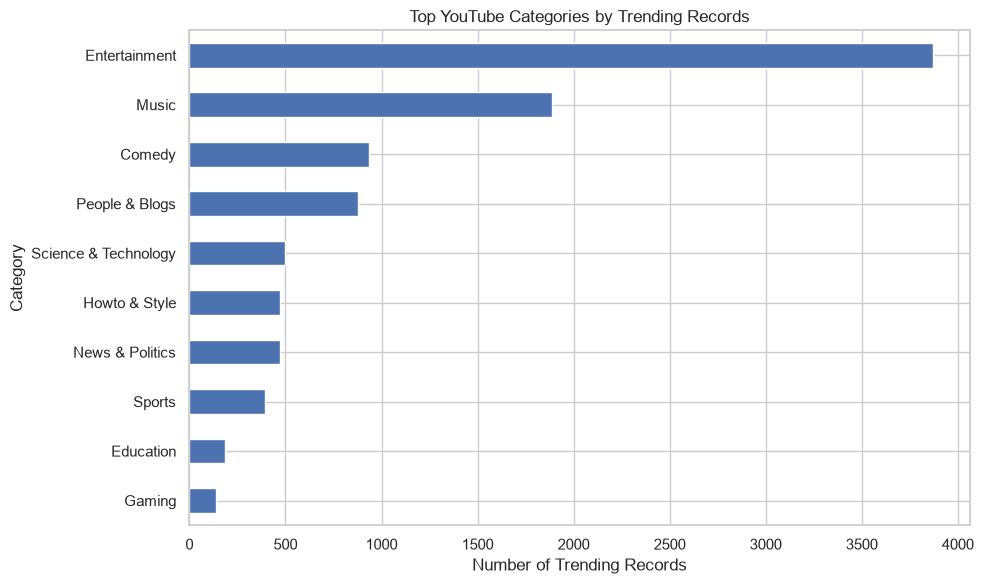

In [33]:
plt.figure(figsize=(10, 6))

category_summary.sort_values().plot(kind='barh')

plt.title('Top YouTube Categories by Trending Records')
plt.xlabel('Number of Trending Records')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

## 8. Unique Video Analysis

Identify unique videos by keeping the record with the highest view count for each video. This helps remove repeated trending records and analyze each video only once.

The analysis also identifies the top 10 unique videos based on view count.

In [10]:
print([name for name in globals() if not name.startswith('_')])

['In', 'Out', 'get_ipython', 'exit', 'quit', 'open', 'pd', 'np', 'plt', 'sns', 'os', 'file_path', 'df']


In [14]:
df_clean = df.drop_duplicates()

In [15]:
print(unique_videos.columns.tolist())

['video_id', 'title', 'publishedAt', 'channelId', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'description']


In [17]:
 # ============================================
# STEP 12: UNIQUE VIDEO ANALYSIS
# ============================================

unique_videos = (
    df_clean
    .sort_values('view_count', ascending=False)
    .drop_duplicates(subset='video_id')
    .reset_index(drop=True)
)

print("========== UNIQUE VIDEO ANALYSIS ==========")

print("Original cleaned records :", len(df_clean))
print("Unique videos            :", len(unique_videos))
print("Repeated records removed :", len(df_clean) - len(unique_videos))

# Top 10 unique videos
top_unique_videos = unique_videos[
    ['video_id',
     'title',
     'channelTitle',
     'categoryId',
     'view_count',
     'likes',
     'comment_count']
].head(10)

print("\n========== TOP 10 UNIQUE VIDEOS ==========")

display(top_unique_videos)

========== UNIQUE VIDEO ANALYSIS ==========
Original cleaned records : 9996
Unique videos            : 2826
Repeated records removed : 7170

========== TOP 10 UNIQUE VIDEOS ==========


,video_id,title,channelTitle,categoryId,view_count,likes,comment_count
0,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,10,253995993,16115240,6249727
1,vRXZj0DzXIA,BLACKPINK - 'Ice Cream (with Selena Gomez)' M/V,BLACKPINK,10,184778248,11795683,2736021
2,dyRsYk0LyA8,BLACKPINK – ‘Lovesick Girls’ M/V,BLACKPINK,10,73552077,6033570,1279238
3,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,FoxStarHindi,24,66344227,680408,1080479
4,oxoWhyS9buA,BTS (방탄소년단) 'Dynamite' Official Teaser,Big Hit Labels,10,62644434,6185031,992639
5,Dz1DjSRElDo,#BeTheInfinite feat. MS Dhoni,OPPO Mobile India,28,52815033,256352,3807
6,CK6YDJdUJ90,"realme 7 & 7 Pro | Capture Sharper, Charge Faster",realme India,28,52187199,145308,825
7,nS1dOZ5HFZQ,Sounds of India | A one of a kind National Anthem,Google India,28,49247948,439603,0
8,BV2FdDmGiW0,BTS (방탄소년단) 'Dynamite' Official MV (B-side),Big Hit Labels,10,45596902,5951288,382374
9,eO1cTboDitc,OPPO F17 Pro | Ultra Sleek+AI Color Portrait |...,OPPO Mobile India,28,39583895,86426,0


### 8.1 Top 10 Unique Videos by Views

Visualize the top 10 unique YouTube videos based on their view counts using a horizontal bar chart.

In [4]:
import matplotlib.pyplot as plt

 unique video dataset

In [19]:
 # Create unique video dataset
unique_videos = (
    df_clean
    .sort_values('view_count', ascending=False)
    .drop_duplicates(subset='video_id')
    .reset_index(drop=True)
)

# Select top 10 unique videos
top_unique_videos = unique_videos[
    ['video_id', 'title', 'channelTitle',
     'categoryId', 'view_count', 'likes', 'comment_count']
].head(10)

print("Top 10 unique videos:")
display(top_unique_videos)

Top 10 unique videos:


,video_id,title,channelTitle,categoryId,view_count,likes,comment_count
0,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,10,253995993,16115240,6249727
1,vRXZj0DzXIA,BLACKPINK - 'Ice Cream (with Selena Gomez)' M/V,BLACKPINK,10,184778248,11795683,2736021
2,dyRsYk0LyA8,BLACKPINK – ‘Lovesick Girls’ M/V,BLACKPINK,10,73552077,6033570,1279238
3,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,FoxStarHindi,24,66344227,680408,1080479
4,oxoWhyS9buA,BTS (방탄소년단) 'Dynamite' Official Teaser,Big Hit Labels,10,62644434,6185031,992639
5,Dz1DjSRElDo,#BeTheInfinite feat. MS Dhoni,OPPO Mobile India,28,52815033,256352,3807
6,CK6YDJdUJ90,"realme 7 & 7 Pro | Capture Sharper, Charge Faster",realme India,28,52187199,145308,825
7,nS1dOZ5HFZQ,Sounds of India | A one of a kind National Anthem,Google India,28,49247948,439603,0
8,BV2FdDmGiW0,BTS (방탄소년단) 'Dynamite' Official MV (B-side),Big Hit Labels,10,45596902,5951288,382374
9,eO1cTboDitc,OPPO F17 Pro | Ultra Sleek+AI Color Portrait |...,OPPO Mobile India,28,39583895,86426,0


 TOP 10 UNIQUE VIDEOS CHART

C:\Users\priya\AppData\Local\Temp\ipykernel_2984\2644416764.py:23: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_2984\2644416764.py:23: UserWarning: Glyph 53444 (\N{HANGUL SYLLABLE TAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_2984\2644416764.py:23: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_2984\2644416764.py:23: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_2984\2644416764.py:23: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missin

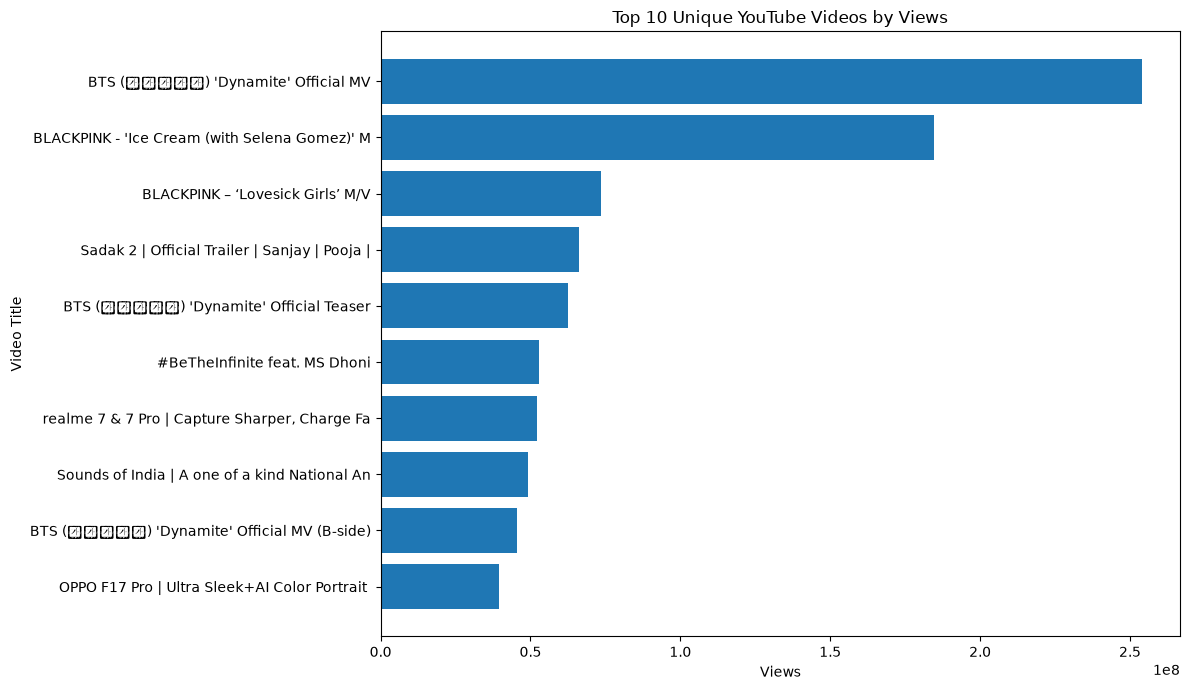

In [20]:
# ============================================
# STEP 12B: TOP 10 UNIQUE VIDEOS CHART
# ============================================

plt.figure(figsize=(12, 7))

plt.barh(
    range(len(top_unique_videos)),
    top_unique_videos['view_count']
)

plt.yticks(
    range(len(top_unique_videos)),
    top_unique_videos['title'].str[:45]
)

plt.xlabel('Views')
plt.ylabel('Video Title')
plt.title('Top 10 Unique YouTube Videos by Views')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

TRENDING DURATION ANALYSIS

In [36]:
# ============================================
# STEP 13: TRENDING DURATION ANALYSIS
# ============================================

# Count the number of unique trending dates for each video
trending_duration = (
    df_clean.groupby(
        ['video_id', 'title', 'channelTitle', 'category_name']
    )['trending_date']
    .nunique()
    .reset_index(name='trending_days')
)

# Sort by number of trending days
trending_duration = trending_duration.sort_values(
    'trending_days',
    ascending=False
).reset_index(drop=True)

print("========== TRENDING DURATION ANALYSIS ==========")

print("Number of unique videos:",
      trending_duration['video_id'].nunique())

print("Maximum trending duration:",
      trending_duration['trending_days'].max(),
      "days")

print("Average trending duration:",
      round(trending_duration['trending_days'].mean(), 2),
      "days")

print("\n========== TOP 10 LONGEST-TRENDING VIDEOS ==========")

top_trending = trending_duration.head(10)

display(top_trending)

========== TRENDING DURATION ANALYSIS ==========
Number of unique videos: 2826
Maximum trending duration: 11 days
Average trending duration: 3.46 days

========== TOP 10 LONGEST-TRENDING VIDEOS ==========


,video_id,title,channelTitle,category_name,trending_days
0,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,FoxStarHindi,Entertainment,11
1,gdZLi9oWNZg,BTS (방탄소년단) 'Dynamite' Official MV,Big Hit Labels,Music,10
2,x-KbnJ9fvJc,Kya Baat Aa : Karan Aujla (Official Video) Tan...,Rehaan Records,Music,9
3,QWVKVcuEpBc,Driving Our Car Underwater | गाडी को पानी में ...,Crazy XYZ,Science & Technology,9
4,HARdHQb1Li4,Chocolate - Tony Kakkar ft. Riyaz Aly & Avneet...,Desi Music Factory,Music,9
5,Dcu8QrSC2RI,GULZAAR CHHANIWALA - BABU DEGYA ( Official Vid...,Gulzaar Chhaniwala,Music,9
6,boHP_GuoDwU,Badi Behan Vs Choti Behan | Sanjhalika Vlog,Sanjhalika Vlog,People & Blogs,9
7,0mSZE5wxKt4,GULZAAR CHHANIWALA | THANDI THANDI (Official V...,Speed Records Haryanvi,Music,9
8,dCmp56tSSmA,Diljit Dosanjh: Born To Shine (Official Music ...,Diljit Dosanjh,Music,9
9,vRXZj0DzXIA,BLACKPINK - 'Ice Cream (with Selena Gomez)' M/V,BLACKPINK,Music,9


 TRENDING DURATION VISUALIZATION

C:\Users\priya\AppData\Local\Temp\ipykernel_10388\4131824023.py:23: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_10388\4131824023.py:23: UserWarning: Glyph 53444 (\N{HANGUL SYLLABLE TAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_10388\4131824023.py:23: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_10388\4131824023.py:23: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_10388\4131824023.py:23: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\priya\AppData\Local\Temp\ipykernel_10388\4131824023.py:23: UserWarning: Glyph 2327 (\N{DEVANAGARI LETTER GA}) missing from font(s) Arial.
  plt.tight

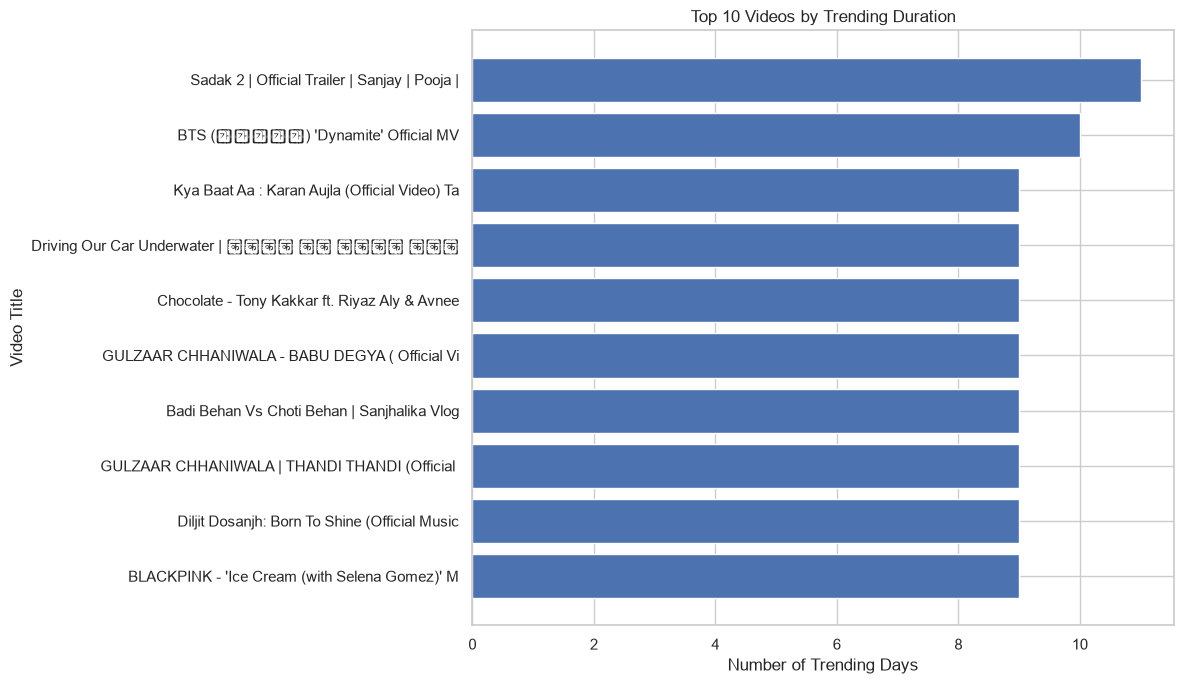

In [25]:
# ============================================
# STEP 13B: TRENDING DURATION VISUALIZATION
# ============================================

plt.figure(figsize=(12, 7))

plt.barh(
    range(len(top_trending)),
    top_trending['trending_days']
)

plt.yticks(
    range(len(top_trending)),
    top_trending['title'].str[:45]
)

plt.xlabel('Number of Trending Days')
plt.ylabel('Video Title')
plt.title('Top 10 Videos by Trending Duration')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [37]:
from textblob import TextBlob

print("TextBlob imported successfully!")

TextBlob imported successfully!


 SENTIMENT ANALYSIS OF VIDEO TITLES

In [38]:
# ============================================
# STEP 14A: SENTIMENT ANALYSIS OF VIDEO TITLES
# ============================================

from textblob import TextBlob

# Function to calculate sentiment
def get_sentiment(text):
    polarity = TextBlob(str(text)).sentiment.polarity

    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"


# Apply sentiment analysis to video titles
df_clean['title_sentiment'] = df_clean['title'].apply(get_sentiment)


# Count each sentiment
sentiment_counts = df_clean['title_sentiment'].value_counts()


print("========== TITLE SENTIMENT ANALYSIS ==========")

print("\nSentiment counts:")
display(sentiment_counts)


# Calculate percentages
sentiment_percentage = (
    df_clean['title_sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nSentiment percentages:")
display(sentiment_percentage)

========== TITLE SENTIMENT ANALYSIS ==========

Sentiment counts:


title_sentiment
Neutral     6181
Positive    3223
Negative     592
Name: count, dtype: int64


Sentiment percentages:


title_sentiment
Neutral     61.83
Positive    32.24
Negative     5.92
Name: proportion, dtype: float64

SENTIMENT DISTRIBUTION CHART

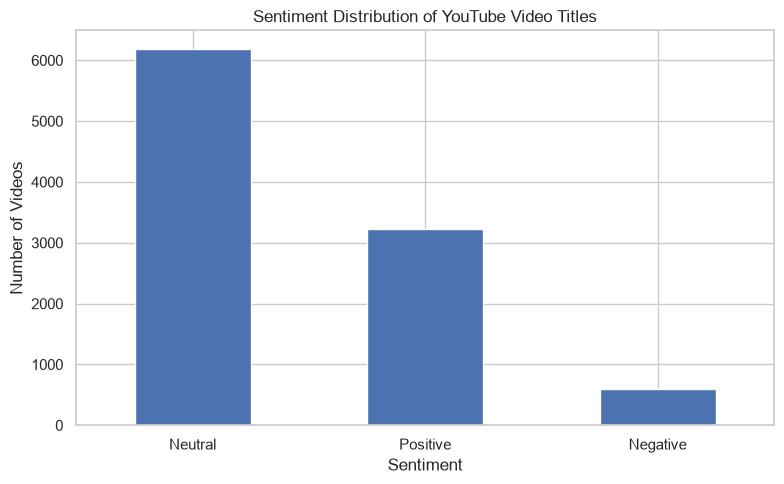

In [29]:
# ============================================
# STEP 14B: SENTIMENT DISTRIBUTION CHART
# ============================================

import matplotlib.pyplot as plt

sentiment_counts = df_clean['title_sentiment'].value_counts()

plt.figure(figsize=(8, 5))

sentiment_counts.plot(
    kind='bar'
)

plt.title('Sentiment Distribution of YouTube Video Titles')
plt.xlabel('Sentiment')
plt.ylabel('Number of Videos')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

 ENGAGEMENT BY SENTIMENT

========== AVERAGE ENGAGEMENT BY SENTIMENT ==========
                 view_count      likes  comment_count
title_sentiment                                      
Negative         1820415.07  127144.96       59627.28
Neutral          2805135.54  163401.88       26086.47
Positive         2552645.87  115192.40       15453.83


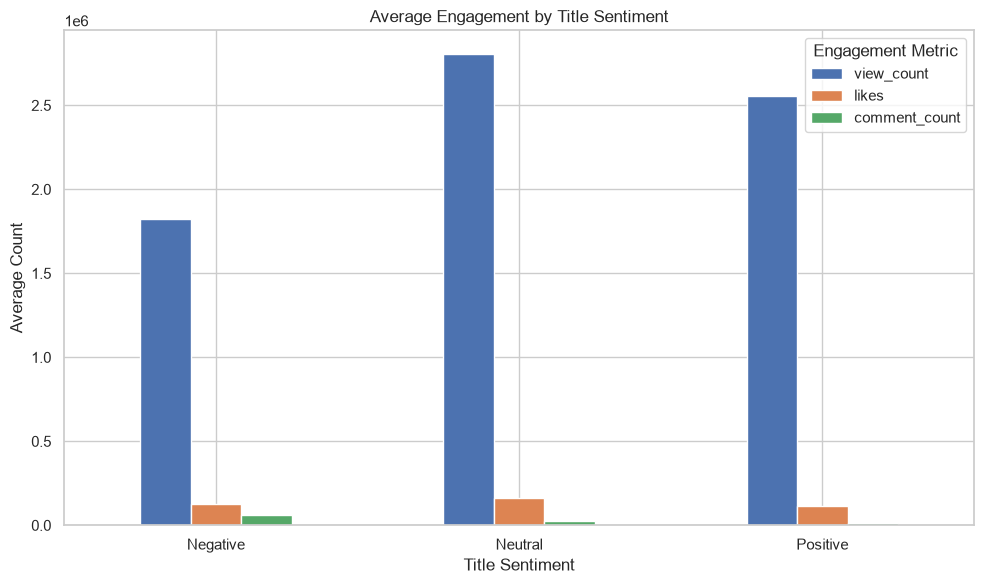

In [39]:
# ============================================
# STEP 15: ENGAGEMENT BY SENTIMENT
# ============================================

sentiment_engagement = df_clean.groupby('title_sentiment')[
    ['view_count', 'likes', 'comment_count']
].mean().round(2)

print("========== AVERAGE ENGAGEMENT BY SENTIMENT ==========")
print(sentiment_engagement)

# Create chart
sentiment_engagement.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Engagement by Title Sentiment')
plt.xlabel('Title Sentiment')
plt.ylabel('Average Count')
plt.xticks(rotation=0)
plt.legend(title='Engagement Metric')

plt.tight_layout()
plt.show()

 CATEGORY-WISE ENGAGEMENT ANALYSIS

========== AVERAGE ENGAGEMENT BY CATEGORY ==========
                       view_count      likes  comment_count
category_name                                              
Music                  6717911.51  429140.03       94822.56
Gaming                 3658016.21  221817.62       17808.23
Science & Technology   3410073.73  135130.40       11789.70
Sports                 2651494.21   93893.97        4982.16
Film & Animation       2466885.68   87480.06       18977.75
Entertainment          1773694.33   69687.54        8964.42
Comedy                 1773095.06  148772.67       10993.93
People & Blogs          984755.33   58080.89        5136.38
Howto & Style           951034.45   46123.36        4098.82
News & Politics         888865.01   25149.03        4507.08
Education               740822.49   32652.25        5003.16
Autos & Vehicles        543284.31   16474.56        1326.97
Travel & Events         413452.66   26227.58        6624.42
Nonprofits & Activism   294521.44    9724.75   

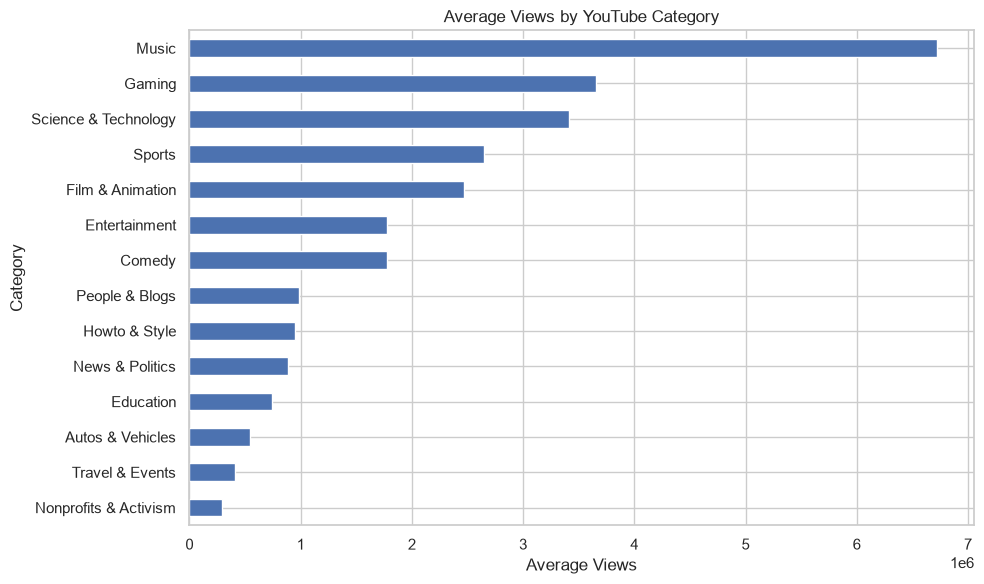

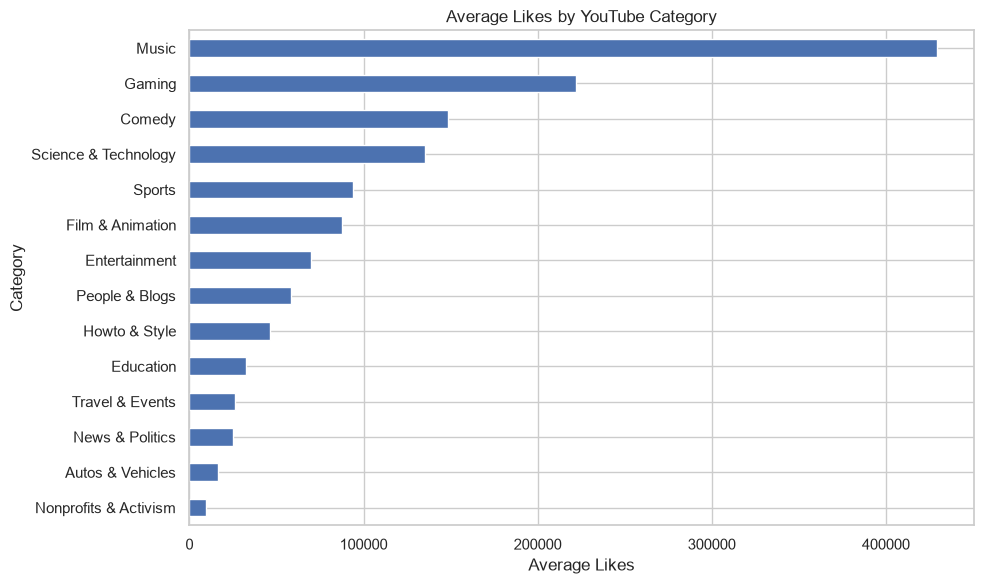

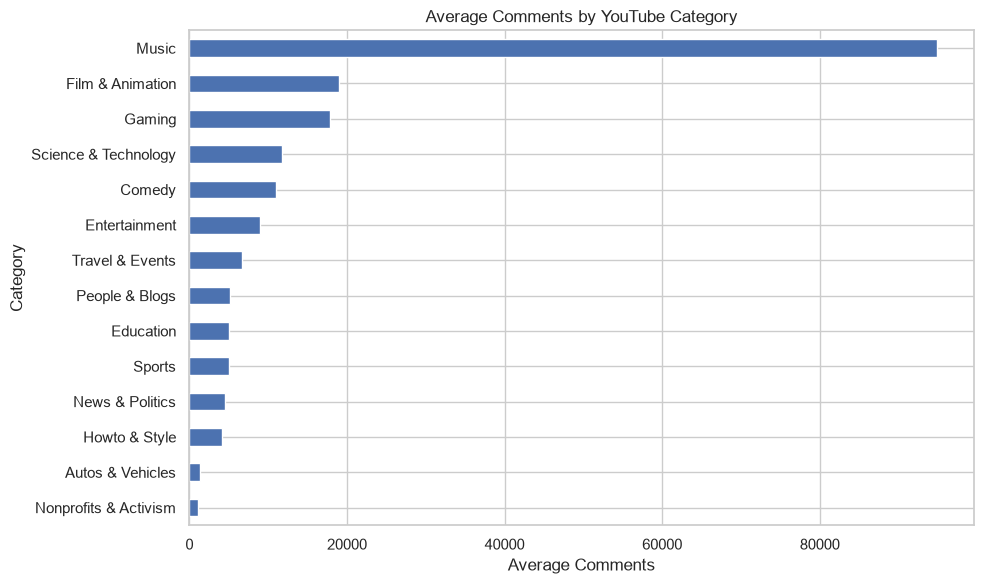

In [40]:
# ============================================
# STEP 16: CATEGORY-WISE ENGAGEMENT ANALYSIS
# ============================================

category_engagement = df_clean.groupby('category_name')[
    ['view_count', 'likes', 'comment_count']
].mean().sort_values(
    'view_count',
    ascending=False
).round(2)

print("========== AVERAGE ENGAGEMENT BY CATEGORY ==========")
print(category_engagement)

# --------------------------------------------
# Chart 1: Average Views by Category
# --------------------------------------------

plt.figure(figsize=(10, 6))

category_engagement['view_count'].sort_values().plot(
    kind='barh'
)

plt.title('Average Views by YouTube Category')
plt.xlabel('Average Views')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

# --------------------------------------------
# Chart 2: Average Likes by Category
# --------------------------------------------

plt.figure(figsize=(10, 6))

category_engagement['likes'].sort_values().plot(
    kind='barh'
)

plt.title('Average Likes by YouTube Category')
plt.xlabel('Average Likes')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

# --------------------------------------------
# Chart 3: Average Comments by Category
# --------------------------------------------

plt.figure(figsize=(10, 6))

category_engagement['comment_count'].sort_values().plot(
    kind='barh'
)

plt.title('Average Comments by YouTube Category')
plt.xlabel('Average Comments')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

ENGAGEMENT RATE ANALYSIS

========== ENGAGEMENT RATE STATISTICS ==========
count    9996.00
mean        6.06
std         5.33
min         0.02
25%         1.87
50%         4.71
75%         8.63
max        73.18
Name: engagement_rate, dtype: float64

========== TOP 10 VIDEOS BY ENGAGEMENT RATE ==========


,video_id,title,channelTitle,category_name,view_count,likes,comment_count,engagement_rate
2933,gdMf2XYGdGY,Celebrate Onam #WithMe🔥🔥🔥 || നിങ്ങള്‍ക്കുള്ള ഓ...,Jayaraj G Nath,Science & Technology,109318,42424,37570,73.175506
3154,gdMf2XYGdGY,Celebrate Onam #WithMe🔥🔥🔥 || നിങ്ങള്‍ക്കുള്ള ഓ...,Jayaraj G Nath,Science & Technology,140775,49748,44474,66.930918
3397,gdMf2XYGdGY,Celebrate Onam #WithMe🔥🔥🔥 || നിങ്ങള്‍ക്കുള്ള ഓ...,Jayaraj G Nath,Science & Technology,152364,52181,47003,65.096742
4193,2L6gsn7rGqI,GAME (Full Video) Shooter Kahlon | Sidhu Moo...,5911 Records,Music,4365130,578253,1907697,56.950194
1745,edhddpkRLS4,New Motorcycle Give away To My Subscribers!! /...,Mallu Traveler,Travel & Events,220711,47258,76377,56.016692
2039,edhddpkRLS4,New Motorcycle Give away To My Subscribers!! /...,Mallu Traveler,Travel & Events,316550,57573,96088,48.542410
2245,edhddpkRLS4,New TVS apache Give away To My Subscribers!! /...,Mallu Traveler,Travel & Events,355006,61526,103543,46.497524
3663,lK_lhOEzRgY,भारतीय अर्थव्यवस्था 40 वर्षों में पहली बार भार...,Rahul Gandhi,News & Politics,91012,34589,6160,44.773217
4264,WPtFlTMZg_c,मोदी जी का ‘कैश-मुक्त’ भारत दरअसल ‘मज़दूर-किसा...,Rahul Gandhi,News & Politics,121214,45181,7049,43.089082
7600,WRoZgfjzGNQ,BTS (방탄소년단) 'Dynamite' ('70s remix) MV,BANGTANTV,Music,4225489,1575867,69532,38.939848



========== AVERAGE ENGAGEMENT RATE BY CATEGORY ==========
category_name
Gaming                   10.40
Science & Technology      9.99
Travel & Events           8.84
Comedy                    8.44
Education                 7.23
Music                     7.01
People & Blogs            6.66
Film & Animation          5.67
Howto & Style             4.99
Sports                    4.95
Nonprofits & Activism     4.80
Entertainment             4.72
Autos & Vehicles          4.51
News & Politics           3.50
Name: engagement_rate, dtype: float64


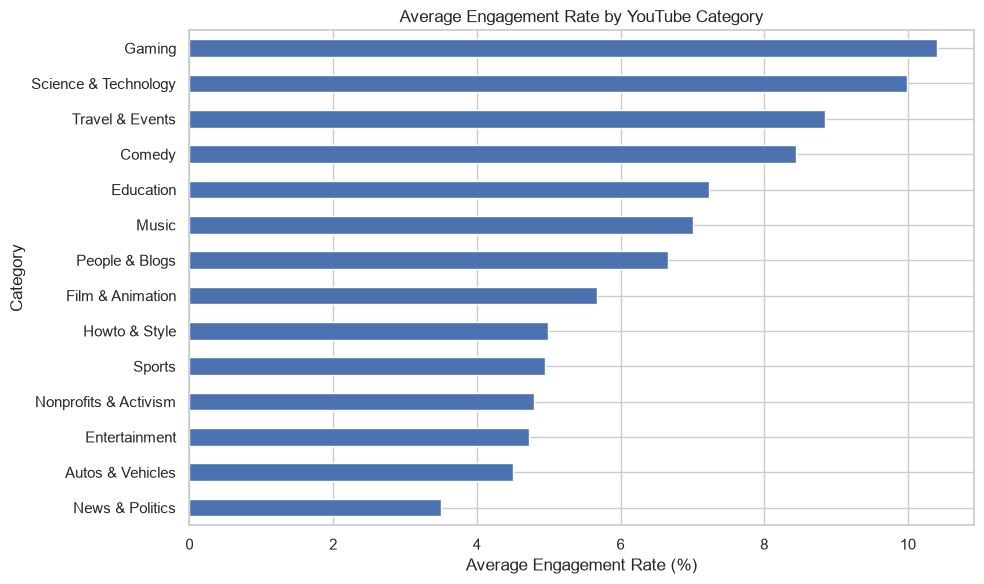

In [42]:
# ============================================
# STEP 17: ENGAGEMENT RATE ANALYSIS
# ============================================

# Calculate engagement rate
df_clean['engagement_rate'] = (
    (df_clean['likes'] + df_clean['comment_count'])
    / df_clean['view_count']
) * 100

# Remove any infinite or invalid values
df_clean['engagement_rate'] = df_clean['engagement_rate'].replace(
    [np.inf, -np.inf], np.nan
)

df_clean['engagement_rate'] = df_clean['engagement_rate'].fillna(0)

# Overall engagement statistics
print("========== ENGAGEMENT RATE STATISTICS ==========")
print(
    df_clean['engagement_rate'].describe().round(2)
)

# Top 10 videos by engagement rate
top_engagement = df_clean.sort_values(
    'engagement_rate',
    ascending=False
)[
    ['video_id', 'title', 'channelTitle',
     'category_name', 'view_count',
     'likes', 'comment_count', 'engagement_rate']
].head(10)

print("\n========== TOP 10 VIDEOS BY ENGAGEMENT RATE ==========")
display(top_engagement)

# Average engagement rate by category
category_rate = df_clean.groupby(
    'category_name'
)['engagement_rate'].mean().sort_values(
    ascending=False
).round(2)

print("\n========== AVERAGE ENGAGEMENT RATE BY CATEGORY ==========")
print(category_rate)

# Chart
plt.figure(figsize=(10, 6))

category_rate.sort_values().plot(
    kind='barh'
)

plt.title('Average Engagement Rate by YouTube Category')
plt.xlabel('Average Engagement Rate (%)')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

 CORRELATION ANALYSIS

========== CORRELATION MATRIX ==========


,view_count,likes,dislikes,comment_count,engagement_rate
view_count,1.00,0.90,0.27,0.82,0.02
likes,0.90,1.00,0.10,0.83,0.19
dislikes,0.27,0.10,1.00,0.21,-0.01
comment_count,0.82,0.83,0.21,1.00,0.12
engagement_rate,0.02,0.19,-0.01,0.12,1.00


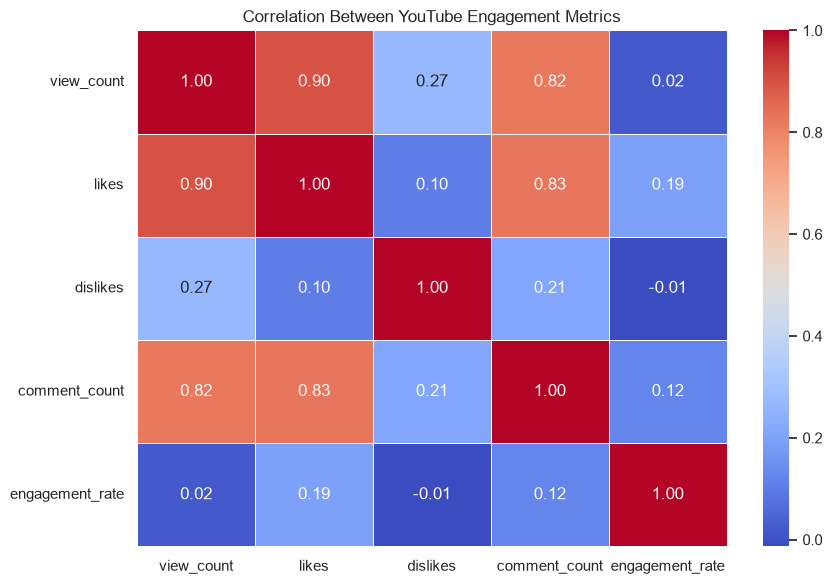

In [43]:
# ============================================
# STEP 18: CORRELATION ANALYSIS
# ============================================

# Select numerical engagement columns
corr_columns = [
    'view_count',
    'likes',
    'dislikes',
    'comment_count',
    'engagement_rate'
]

# Calculate correlation matrix
correlation_matrix = df_clean[corr_columns].corr()

print("========== CORRELATION MATRIX ==========")
display(correlation_matrix.round(2))

# Plot correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between YouTube Engagement Metrics')
plt.tight_layout()
plt.show()

 FINAL SUMMARY

In [44]:
# ============================================
# STEP 19: FINAL SUMMARY - CORRECTED
# ============================================

print("=" * 60)
print("       YOUTUBE TRENDING ANALYTICS - FINAL SUMMARY")
print("=" * 60)

print("\n1. DATASET OVERVIEW")
print("-" * 40)
print("Total cleaned records :", len(df_clean))
print("Total unique videos   :", df_clean['video_id'].nunique())
print("Total channels        :", df_clean['channelTitle'].nunique())
print("Total categories      :", df_clean['category_name'].nunique())

print("\n2. ENGAGEMENT SUMMARY")
print("-" * 40)
print("Total views    :", f"{df_clean['view_count'].sum():,}")
print("Total likes    :", f"{df_clean['likes'].sum():,}")
print("Total dislikes :", f"{df_clean['dislikes'].sum():,}")
print("Total comments :", f"{df_clean['comment_count'].sum():,}")

print("\n3. AVERAGE METRICS")
print("-" * 40)
print("Average views    :", f"{df_clean['view_count'].mean():,.2f}")
print("Average likes    :", f"{df_clean['likes'].mean():,.2f}")
print("Average dislikes :", f"{df_clean['dislikes'].mean():,.2f}")
print("Average comments :", f"{df_clean['comment_count'].mean():,.2f}")
print("Average engagement rate :",
      f"{df_clean['engagement_rate'].mean():.2f}%")

# --------------------------------------------
# TRENDING DURATION
# --------------------------------------------

print("\n4. TRENDING DURATION")
print("-" * 40)

# Calculate trending duration from dates
trending_duration = (
    df_clean.groupby('video_id')['trending_date']
    .agg(['min', 'max'])
)

trending_duration['trending_days'] = (
    trending_duration['max'] - trending_duration['min']
).dt.days + 1

print("Average trending duration :",
      f"{trending_duration['trending_days'].mean():.2f} days")

print("Maximum trending duration :",
      f"{trending_duration['trending_days'].max()} days")

# --------------------------------------------
# TOP CATEGORY
# --------------------------------------------

print("\n5. TOP CATEGORY BY TRENDING RECORDS")
print("-" * 40)

category_counts = df_clean['category_name'].value_counts()

print("Category :", category_counts.index[0])
print("Records  :", category_counts.iloc[0])

# --------------------------------------------
# TOP CHANNEL
# --------------------------------------------

print("\n6. TOP CHANNEL BY TOTAL VIEWS")
print("-" * 40)

channel_views = (
    df_clean.groupby('channelTitle')['view_count']
    .sum()
    .sort_values(ascending=False)
)

print("Channel :", channel_views.index[0])
print("Views   :", f"{channel_views.iloc[0]:,}")

# --------------------------------------------
# TOP UNIQUE VIDEO
# --------------------------------------------

print("\n7. TOP UNIQUE VIDEO BY VIEWS")
print("-" * 40)

unique_videos = df_clean.drop_duplicates(
    subset='video_id',
    keep='last'
)

top_video = unique_videos.loc[
    unique_videos['view_count'].idxmax()
]

print("Title   :", top_video['title'])
print("Channel :", top_video['channelTitle'])
print("Views   :", f"{top_video['view_count']:,}")

# --------------------------------------------
# SENTIMENT
# --------------------------------------------

print("\n8. SENTIMENT DISTRIBUTION")
print("-" * 40)

print(df_clean['title_sentiment'].value_counts())

# --------------------------------------------
# CORRELATION
# --------------------------------------------

print("\n9. CORRELATION HIGHLIGHTS")
print("-" * 40)

print("Views ↔ Likes :",
      round(correlation_matrix.loc['view_count', 'likes'], 2))

print("Views ↔ Comments :",
      round(correlation_matrix.loc['view_count', 'comment_count'], 2))

print("Likes ↔ Comments :",
      round(correlation_matrix.loc['likes', 'comment_count'], 2))

print("Views ↔ Engagement Rate :",
      round(correlation_matrix.loc['view_count',
                                   'engagement_rate'], 2))

print("\n" + "=" * 60)
print("             EDA COMPLETED SUCCESSFULLY")
print("=" * 60)

       YOUTUBE TRENDING ANALYTICS - FINAL SUMMARY

1. DATASET OVERVIEW
----------------------------------------
Total cleaned records : 9996
Total unique videos   : 2826
Total channels        : 914
Total categories      : 14

2. ENGAGEMENT SUMMARY
----------------------------------------
Total views    : 26,643,406,160
Total likes    : 1,456,521,966
Total dislikes : 211,336,209
Total comments : 246,347,521

3. AVERAGE METRICS
----------------------------------------
Average views    : 2,665,406.78
Average likes    : 145,710.48
Average dislikes : 21,142.08
Average comments : 24,644.61
Average engagement rate : 6.06%

4. TRENDING DURATION
----------------------------------------
Average trending duration : 3.55 days
Maximum trending duration : 11 days

5. TOP CATEGORY BY TRENDING RECORDS
----------------------------------------
Category : Entertainment
Records  : 3870

6. TOP CHANNEL BY TOTAL VIEWS
----------------------------------------
Channel : Big Hit Labels
Views   : 2,677,691,540


In [46]:
print(df.columns.tolist())

['video_id', 'title', 'publishedAt', 'channelId', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'description']


 SQL CATEGORY RANKING WITH NAMES

In [49]:
# ============================================
# STEP 21: SQL CATEGORY RANKING WITH NAMES
# ============================================

import sqlite3
import pandas as pd

# Create category mapping
category_mapping = {
    1: "Film & Animation",
    2: "Autos & Vehicles",
    10: "Music",
    17: "Sports",
    19: "Travel & Events",
    20: "Gaming",
    22: "People & Blogs",
    23: "Comedy",
    24: "Entertainment",
    25: "News & Politics",
    26: "Howto & Style",
    27: "Education",
    28: "Science & Technology",
    29: "Nonprofits & Activism"
}

# Create SQLite connection
conn = sqlite3.connect("youtube_trending.db")

# SQL query
query = """
SELECT
    categoryId,
    COUNT(*) AS total_records,
    ROUND(AVG(view_count), 2) AS average_views
FROM youtube_trending
GROUP BY categoryId
ORDER BY average_views DESC;
"""

# Run SQL query
sql_result = pd.read_sql_query(query, conn)

# Convert category IDs to category names
sql_result["category_name"] = sql_result["categoryId"].map(category_mapping)

# Add ranking
sql_result.insert(
    0,
    "Rank",
    range(1, len(sql_result) + 1)
)

# Arrange columns
sql_result = sql_result[
    ["Rank", "category_name", "categoryId",
     "total_records", "average_views"]
]

# Rename columns
sql_result.columns = [
    "Rank",
    "Category",
    "Category ID",
    "Total Records",
    "Average Views"
]

print("\n========== CATEGORY RANKING BY AVERAGE VIEWS ==========")

display(sql_result)

# Close connection
conn.close()


========== CATEGORY RANKING BY AVERAGE VIEWS ==========


,Rank,Category,Category ID,Total Records,Average Views
0,1,Music,10,1888,6717911.51
1,2,Gaming,20,137,3658016.21
2,3,Science & Technology,28,496,3410073.73
3,4,Sports,17,392,2651494.21
4,5,Film & Animation,1,105,2466885.68
5,6,Entertainment,24,3870,1773694.33
6,7,Comedy,23,936,1773095.06
7,8,People & Blogs,22,876,984755.33
8,9,Howto & Style,26,473,951034.45
9,10,News & Politics,25,472,888865.01


In [5]:
import os

us_file = r"C:\Users\priya\Downloads\US_youtube_trending_data.csv"

print("Exists:", os.path.exists(us_file))
print("Is file:", os.path.isfile(us_file))
print("Readable:", os.access(us_file, os.R_OK))

Exists: False
Is file: False
Readable: False


In [8]:
import os

# Search your Downloads folder for the US CSV
downloads = r"C:\Users\priya\Downloads"

for root, folders, files in os.walk(downloads):
    for file in files:
        if "US_youtube_trending_data" in file:
            print("FOUND:")
            print(os.path.join(root, file))

FOUND:
C:\Users\priya\Downloads\US_youtube_trending_data.csv.zip
FOUND:
C:\Users\priya\Downloads\US_youtube_trending_data.csv\US_youtube_trending_data.csv


 LOAD US YOUTUBE DATASET

In [9]:
# ============================================
# STEP 22B: LOAD US YOUTUBE DATASET
# ============================================

import pandas as pd

us_file = r"C:\Users\priya\Downloads\US_youtube_trending_data.csv"

df_us = pd.read_csv(us_file, nrows=10000)

print("US dataset loaded successfully!")
print("US dataset shape:", df_us.shape)

print("\nUS dataset columns:")
print(df_us.columns.tolist())

US dataset loaded successfully!
US dataset shape: (10000, 16)

US dataset columns:
['video_id', 'title', 'publishedAt', 'channelId', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'description']


CLEAN US YOUTUBE DATASET

In [10]:
# ============================================
# STEP 22C: CLEAN US YOUTUBE DATASET
# ============================================

# Make a copy
df_us_clean = df_us.copy()

print("========== ORIGINAL DATA ==========")
print("Rows:", len(df_us_clean))
print("Columns:", len(df_us_clean.columns))

# ------------------------------------------------
# 1. Remove duplicate rows
# ------------------------------------------------
df_us_clean = df_us_clean.drop_duplicates()

# ------------------------------------------------
# 2. Convert date columns
# ------------------------------------------------
df_us_clean['publishedAt'] = pd.to_datetime(
    df_us_clean['publishedAt'],
    errors='coerce'
)

df_us_clean['trending_date'] = pd.to_datetime(
    df_us_clean['trending_date'],
    errors='coerce'
)

# ------------------------------------------------
# 3. Remove rows with missing important values
# ------------------------------------------------
important_columns = [
    'video_id',
    'title',
    'channelTitle',
    'publishedAt',
    'trending_date',
    'view_count',
    'likes',
    'comment_count'
]

df_us_clean = df_us_clean.dropna(
    subset=important_columns
)

# ------------------------------------------------
# 4. Fill missing tags and descriptions
# ------------------------------------------------
df_us_clean['tags'] = df_us_clean['tags'].fillna('')
df_us_clean['description'] = df_us_clean['description'].fillna('')

# ------------------------------------------------
# 5. Make sure numeric columns are numeric
# ------------------------------------------------
numeric_columns = [
    'view_count',
    'likes',
    'dislikes',
    'comment_count'
]

for column in numeric_columns:
    df_us_clean[column] = pd.to_numeric(
        df_us_clean[column],
        errors='coerce'
    )

# ------------------------------------------------
# 6. Remove rows where numeric values are missing
# ------------------------------------------------
df_us_clean = df_us_clean.dropna(
    subset=numeric_columns
)

# ------------------------------------------------
# 7. Create engagement rate
# ------------------------------------------------
df_us_clean['engagement_rate'] = (
    (
        df_us_clean['likes']
        + df_us_clean['comment_count']
    )
    / df_us_clean['view_count']
) * 100

# ------------------------------------------------
# 8. Display cleaning results
# ------------------------------------------------

print("\n========== CLEANING RESULTS ==========")

print("Cleaned rows:", len(df_us_clean))
print("Columns:", len(df_us_clean.columns))

print("\nMissing values:")
print(df_us_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_us_clean.duplicated().sum())

print("\n========== FIRST 5 CLEANED US RECORDS ==========")

display(df_us_clean.head())

========== ORIGINAL DATA ==========
Rows: 10000
Columns: 16

========== CLEANING RESULTS ==========
Cleaned rows: 9999
Columns: 17

Missing values:
video_id             0
title                0
publishedAt          0
channelId            0
channelTitle         0
categoryId           0
trending_date        0
tags                 0
view_count           0
likes                0
dislikes             0
comment_count        0
thumbnail_link       0
comments_disabled    0
ratings_disabled     0
description          0
engagement_rate      0
dtype: int64

Duplicate rows:
0

========== FIRST 5 CLEANED US RECORDS ==========


,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description,engagement_rate
0,3C66w5Z0ixs,I ASKED HER TO BE MY GIRLFRIEND...,2020-08-11 19:20:14+00:00,UCvtRTOMP2TqYqu51xNrqAzg,Brawadis,22,2020-08-12 00:00:00+00:00,brawadis|prank|basketball|skits|ghost|funny vi...,1514614,156908,5855,35313,https://i.ytimg.com/vi/3C66w5Z0ixs/default.jpg,False,False,SUBSCRIBE to BRAWADIS ▶ http://bit.ly/Subscrib...,12.691088
1,M9Pmf9AB4Mo,Apex Legends | Stories from the Outlands – “Th...,2020-08-11 17:00:10+00:00,UC0ZV6M2THA81QT9hrVWJG3A,Apex Legends,20,2020-08-12 00:00:00+00:00,Apex Legends|Apex Legends characters|new Apex ...,2381688,146739,2794,16549,https://i.ytimg.com/vi/M9Pmf9AB4Mo/default.jpg,False,False,"While running her own modding shop, Ramya Pare...",6.855978
2,J78aPJ3VyNs,I left youtube for a month and THIS is what ha...,2020-08-11 16:34:06+00:00,UCYzPXprvl5Y-Sf0g4vX-m6g,jacksepticeye,24,2020-08-12 00:00:00+00:00,jacksepticeye|funny|funny meme|memes|jacksepti...,2038853,353787,2628,40221,https://i.ytimg.com/vi/J78aPJ3VyNs/default.jpg,False,False,I left youtube for a month and this is what ha...,19.324983
3,kXLn3HkpjaA,XXL 2020 Freshman Class Revealed - Official An...,2020-08-11 16:38:55+00:00,UCbg_UMjlHJg_19SZckaKajg,XXL,10,2020-08-12 00:00:00+00:00,xxl freshman|xxl freshmen|2020 xxl freshman|20...,496771,23251,1856,7647,https://i.ytimg.com/vi/kXLn3HkpjaA/default.jpg,False,False,Subscribe to XXL → http://bit.ly/subscribe-xxl...,6.219767
4,VIUo6yapDbc,Ultimate DIY Home Movie Theater for The LaBran...,2020-08-11 15:10:05+00:00,UCDVPcEbVLQgLZX0Rt6jo34A,Mr. Kate,26,2020-08-12 00:00:00+00:00,The LaBrant Family|DIY|Interior Design|Makeove...,1123889,45802,964,2196,https://i.ytimg.com/vi/VIUo6yapDbc/default.jpg,False,False,Transforming The LaBrant Family's empty white ...,4.270706


 US TITLE SENTIMENT ANALYSIS

In [11]:
# ============================================
# STEP 22D: US TITLE SENTIMENT ANALYSIS
# ============================================

from textblob import TextBlob

# Calculate sentiment score
df_us_clean['sentiment_score'] = df_us_clean['title'].apply(
    lambda x: TextBlob(str(x)).sentiment.polarity
)

# Convert score into sentiment category
def classify_sentiment(score):
    if score > 0:
        return 'Positive'
    elif score < 0:
        return 'Negative'
    else:
        return 'Neutral'

df_us_clean['title_sentiment'] = df_us_clean['sentiment_score'].apply(
    classify_sentiment
)

# Count sentiments
sentiment_counts_us = df_us_clean['title_sentiment'].value_counts()

# Calculate percentages
sentiment_percentages_us = (
    df_us_clean['title_sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("========== US TITLE SENTIMENT ANALYSIS ==========")

print("\nSentiment counts:")
print(sentiment_counts_us)

print("\nSentiment percentages:")
print(sentiment_percentages_us)

========== US TITLE SENTIMENT ANALYSIS ==========

Sentiment counts:
title_sentiment
Neutral     6121
Positive    2459
Negative    1419
Name: count, dtype: int64

Sentiment percentages:
title_sentiment
Neutral     61.22
Positive    24.59
Negative    14.19
Name: proportion, dtype: float64


US CATEGORY ANALYSIS

In [12]:
# ============================================
# STEP 22E: US CATEGORY ANALYSIS
# ============================================

# Category names
category_names = {
    1: 'Film & Animation',
    2: 'Autos & Vehicles',
    10: 'Music',
    15: 'Pets & Animals',
    17: 'Sports',
    18: 'Short Movies',
    19: 'Travel & Events',
    20: 'Gaming',
    21: 'Videoblogging',
    22: 'People & Blogs',
    23: 'Comedy',
    24: 'Entertainment',
    25: 'News & Politics',
    26: 'Howto & Style',
    27: 'Education',
    28: 'Science & Technology',
    29: 'Nonprofits & Activism',
    30: 'Movies',
    31: 'Anime/Animation',
    32: 'Action/Adventure',
    33: 'Classics',
    34: 'Comedy',
    35: 'Documentary',
    36: 'Drama',
    37: 'Family',
    38: 'Foreign',
    39: 'Horror',
    40: 'Sci-Fi/Fantasy',
    41: 'Thriller',
    42: 'Shorts',
    43: 'Shows',
    44: 'Trailers'
}

# Create category name column
df_us_clean['category_name'] = df_us_clean['categoryId'].map(category_names)

# Count trending records by category
category_distribution_us = (
    df_us_clean['category_name']
    .value_counts()
)

print("========== US CATEGORY DISTRIBUTION ==========")
print(category_distribution_us)

# Average views by category
category_views_us = (
    df_us_clean
    .groupby('category_name')['view_count']
    .mean()
    .sort_values(ascending=False)
)

print("\n========== US AVERAGE VIEWS BY CATEGORY ==========")
print(category_views_us.round(2))

========== US CATEGORY DISTRIBUTION ==========
category_name
Music                    2301
Entertainment            1847
Sports                   1183
People & Blogs            860
Gaming                    833
Comedy                    582
Science & Technology      508
Howto & Style             463
News & Politics           451
Film & Animation          376
Education                 241
Autos & Vehicles          199
Pets & Animals            102
Travel & Events            44
Nonprofits & Activism       9
Name: count, dtype: int64

========== US AVERAGE VIEWS BY CATEGORY ==========
category_name
Music                    5083525.25
Entertainment            2583660.55
Gaming                   2569538.92
Science & Technology     1954504.83
People & Blogs           1925852.50
Film & Animation         1742814.28
Sports                   1522976.21
Nonprofits & Activism    1380105.56
Howto & Style            1273005.58
Comedy                   1189496.46
Autos & Vehicles         1030426.48
E

 US SQL CATEGORY RANKING

In [13]:
# ============================================
# STEP 22F: US SQL CATEGORY RANKING
# ============================================

import sqlite3
import pandas as pd

# Create SQLite database
conn_us = sqlite3.connect("youtube_trending_us.db")

# Save US cleaned data into SQLite
df_us_clean.to_sql(
    "youtube_trending_us",
    conn_us,
    if_exists="replace",
    index=False
)

print("US dataset successfully loaded into SQLite!")

# ============================================
# SQL QUERY
# Rank categories by average views
# ============================================

query_us = """
SELECT
    category_name AS category,
    COUNT(*) AS total_records,
    ROUND(AVG(view_count), 2) AS average_views
FROM youtube_trending_us
WHERE category_name IS NOT NULL
GROUP BY category_name
ORDER BY average_views DESC;
"""

category_ranking_us = pd.read_sql_query(
    query_us,
    conn_us
)

print("\n========== US CATEGORY RANKING BY AVERAGE VIEWS ==========")

display(category_ranking_us)

# Close database
conn_us.close()

US dataset successfully loaded into SQLite!

========== US CATEGORY RANKING BY AVERAGE VIEWS ==========


,category,total_records,average_views
0,Music,2301,5083525.25
1,Entertainment,1847,2583660.55
2,Gaming,833,2569538.92
3,Science & Technology,508,1954504.83
4,People & Blogs,860,1925852.50
5,Film & Animation,376,1742814.28
6,Sports,1183,1522976.21
7,Nonprofits & Activism,9,1380105.56
8,Howto & Style,463,1273005.58
9,Comedy,582,1189496.46


In [18]:
import os

downloads = r"C:\Users\priya\Downloads"

for root, dirs, files in os.walk(downloads):
    for file in files:
        if "IN_youtube_trending_data" in file:
            print(os.path.join(root, file))

C:\Users\priya\Downloads\IN_youtube_trending_data.csv.zip
C:\Users\priya\Downloads\IN_youtube_trending_data.csv\IN_youtube_trending_data.csv


In [19]:
import pandas as pd

india_file = r"C:\Users\priya\Downloads\IN_youtube_trending_data.csv"

df = pd.read_csv(india_file, nrows=10000)

# Remove duplicate rows
df_clean = df.drop_duplicates().copy()

print("India dataset loaded successfully!")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

India dataset loaded successfully!
Original rows: 10000
Cleaned rows: 9996
Columns: 16


CREATE ENGAGEMENT RATE

In [20]:
# ============================================
# INDIA: CREATE ENGAGEMENT RATE
# ============================================

df_clean['engagement_rate'] = (
    (df_clean['likes'] + df_clean['comment_count'])
    / df_clean['view_count']
) * 100

print("India engagement rate created successfully!")
print(df_clean[['view_count', 'likes', 'comment_count', 'engagement_rate']].head())

India engagement rate created successfully!
   view_count   likes  comment_count  engagement_rate
0     9885899  224925         350210         5.817731
1    11308046  655450         405146         9.379127
2     9140911  296533          30058         3.572850
3    23564512  743931         136942         3.738134
4     6783649  268817          22984         4.301534


In [21]:
# ============================================
# STEP 22: INDIA VS USA COMPARISON
# ============================================

region_summary = pd.DataFrame({
    'Region': ['India', 'USA'],

    'Average Views': [
        df_clean['view_count'].mean(),
        df_us_clean['view_count'].mean()
    ],

    'Average Likes': [
        df_clean['likes'].mean(),
        df_us_clean['likes'].mean()
    ],

    'Average Comments': [
        df_clean['comment_count'].mean(),
        df_us_clean['comment_count'].mean()
    ],

    'Average Engagement Rate': [
        df_clean['engagement_rate'].mean(),
        df_us_clean['engagement_rate'].mean()
    ]
})

# Round the values
region_summary[
    ['Average Views',
     'Average Likes',
     'Average Comments',
     'Average Engagement Rate']
] = region_summary[
    ['Average Views',
     'Average Likes',
     'Average Comments',
     'Average Engagement Rate']
].round(2)

print("========== INDIA VS USA COMPARISON ==========")
print(region_summary)

========== INDIA VS USA COMPARISON ==========
  Region  Average Views  Average Likes  Average Comments  \
0  India     2665406.78      145710.48          24644.61   
1    USA     2596620.28      163330.36          21348.34   

   Average Engagement Rate  
0                     6.06  
1                     6.70  


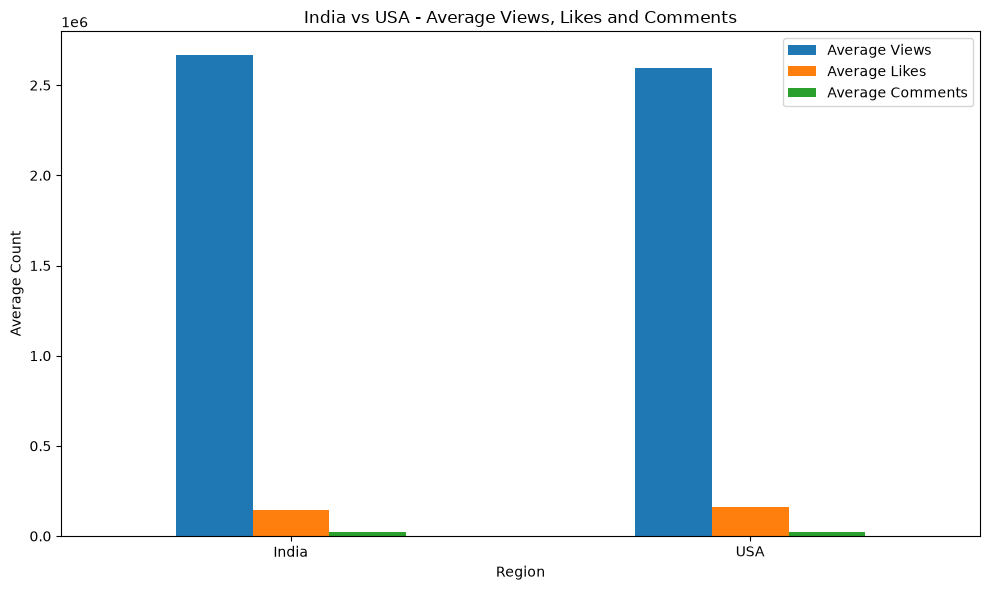

In [23]:
# ============================================
# CHART 1: INDIA VS USA ENGAGEMENT METRICS
# ============================================

metrics = region_summary.set_index('Region')[
    ['Average Views', 'Average Likes', 'Average Comments']
]

metrics.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('India vs USA - Average Views, Likes and Comments')
plt.xlabel('Region')
plt.ylabel('Average Count')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

INDIA VS USA ENGAGEMENT RATE

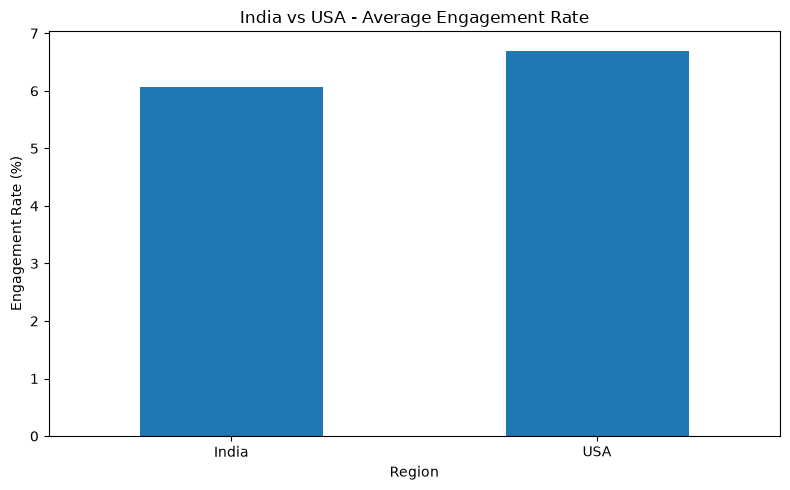

In [24]:
# ============================================
# CHART 2: INDIA VS USA ENGAGEMENT RATE
# ============================================

engagement = region_summary.set_index('Region')['Average Engagement Rate']

engagement.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('India vs USA - Average Engagement Rate')
plt.xlabel('Region')
plt.ylabel('Engagement Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

TRENDING DURATION ANALYSIS

In [25]:
# ============================================
# STEP 23: TRENDING DURATION ANALYSIS
# ============================================

# Make sure dates are datetime
df_clean['trending_date'] = pd.to_datetime(df_clean['trending_date'])
df_clean['publishedAt'] = pd.to_datetime(df_clean['publishedAt'])

# Calculate days from publication to trending date
df_clean['trending_days'] = (
    df_clean['trending_date'].dt.date -
    df_clean['publishedAt'].dt.date
).apply(lambda x: x.days)

print("========== TRENDING DURATION ==========")

print("Average trending duration:",
      round(df_clean['trending_days'].mean(), 2), "days")

print("Maximum trending duration:",
      df_clean['trending_days'].max(), "days")

print("Minimum trending duration:",
      df_clean['trending_days'].min(), "days")

print("\n========== TRENDING DURATION SUMMARY ==========")
print(df_clean['trending_days'].describe())

========== TRENDING DURATION ==========
Average trending duration: 2.62 days
Maximum trending duration: 26 days
Minimum trending duration: 0 days

========== TRENDING DURATION SUMMARY ==========
count    9996.000000
mean        2.617847
std         1.815893
min         0.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        26.000000
Name: trending_days, dtype: float64


“YouTube Trending Duration Distribution – India”

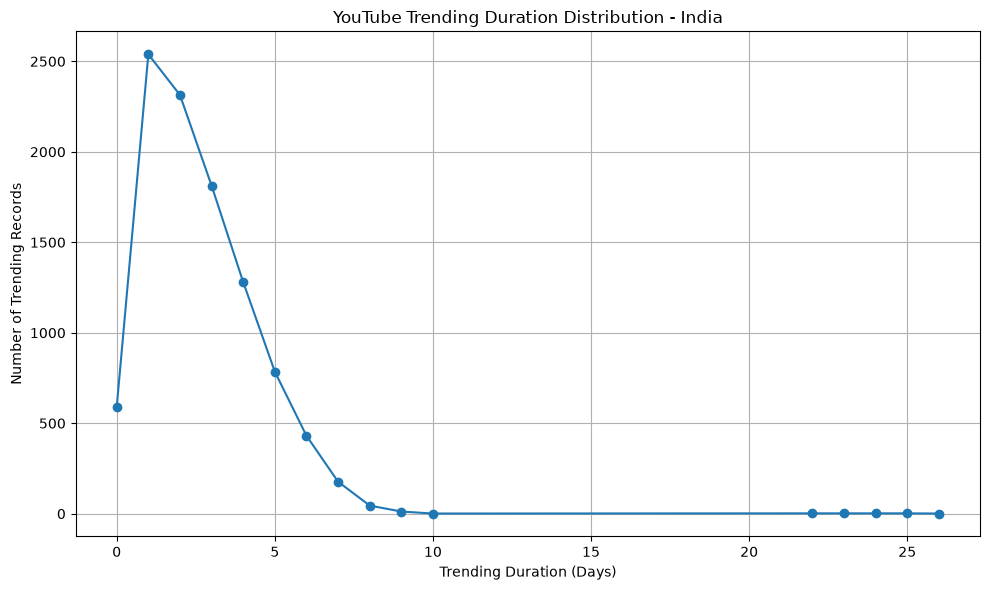

In [26]:
# ============================================
# STEP 24: TRENDING DURATION VISUALIZATION
# ============================================

plt.figure(figsize=(10, 6))

df_clean['trending_days'].value_counts().sort_index().plot(
    kind='line',
    marker='o'
)

plt.title('YouTube Trending Duration Distribution - India')
plt.xlabel('Trending Duration (Days)')
plt.ylabel('Number of Trending Records')
plt.grid(True)

plt.tight_layout()
plt.show()

 USA TRENDING DURATION

In [27]:
# ============================================
# STEP 26: USA TRENDING DURATION
# ============================================

df_us_clean['trending_date'] = pd.to_datetime(
    df_us_clean['trending_date']
)

df_us_clean['publishedAt'] = pd.to_datetime(
    df_us_clean['publishedAt']
)

df_us_clean['trending_days'] = (
    df_us_clean['trending_date'].dt.date -
    df_us_clean['publishedAt'].dt.date
).apply(lambda x: x.days)

print("========== USA TRENDING DURATION ==========")

print(
    "Average trending duration:",
    round(df_us_clean['trending_days'].mean(), 2),
    "days"
)

print(
    "Maximum trending duration:",
    df_us_clean['trending_days'].max(),
    "days"
)

print(
    "Minimum trending duration:",
    df_us_clean['trending_days'].min(),
    "days"
)

print("\n========== USA TRENDING DURATION SUMMARY ==========")
print(df_us_clean['trending_days'].describe())

========== USA TRENDING DURATION ==========
Average trending duration: 3.48 days
Maximum trending duration: 31 days
Minimum trending duration: 0 days

========== USA TRENDING DURATION SUMMARY ==========
count    9999.000000
mean        3.477348
std         1.931426
min         0.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        31.000000
Name: trending_days, dtype: float64


## **STEP 23: INDIA VS USA TRENDING DURATION**

In [28]:
# ============================================
# STEP 23: INDIA VS USA TRENDING DURATION
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create comparison table
duration_comparison = pd.DataFrame({
    'Region': ['India', 'USA'],
    'Average Trending Days': [
        df_clean['trending_days'].mean(),
        df_us_clean['trending_days'].mean()
    ],
    'Median Trending Days': [
        df_clean['trending_days'].median(),
        df_us_clean['trending_days'].median()
    ],
    'Maximum Trending Days': [
        df_clean['trending_days'].max(),
        df_us_clean['trending_days'].max()
    ],
    'Minimum Trending Days': [
        df_clean['trending_days'].min(),
        df_us_clean['trending_days'].min()
    ]
})

print("========== INDIA VS USA TRENDING DURATION ==========")
print(duration_comparison.round(2))

========== INDIA VS USA TRENDING DURATION ==========
  Region  Average Trending Days  Median Trending Days  Maximum Trending Days  \
0  India                   2.62                   2.0                     26   
1    USA                   3.48                   3.0                     31   

   Minimum Trending Days  
0                      0  
1                      0  


## **TRENDING DURATION COMPARISON GRAPH**

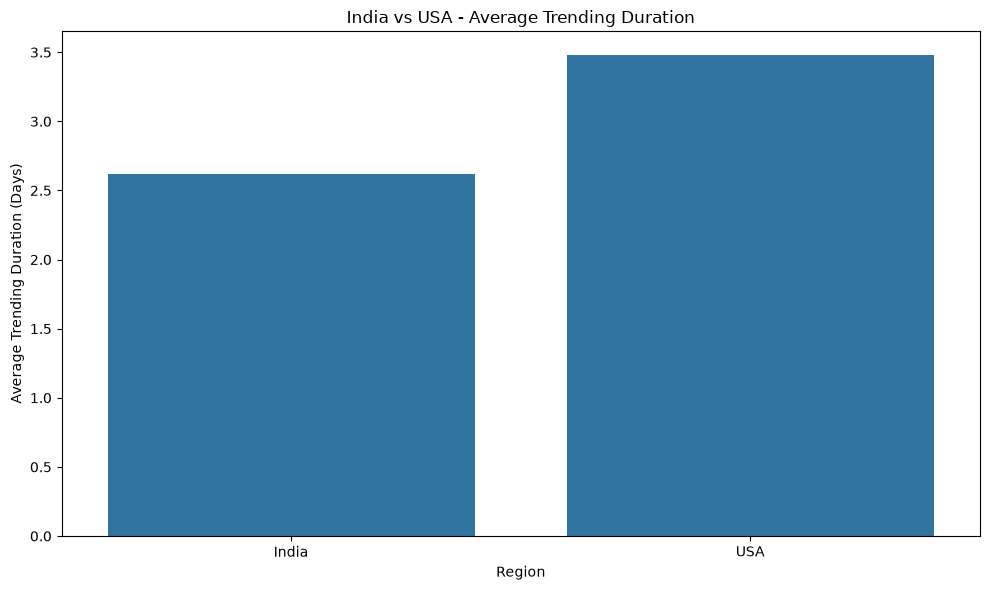

In [29]:
# ============================================
# TRENDING DURATION COMPARISON GRAPH
# ============================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=duration_comparison,
    x='Region',
    y='Average Trending Days'
)

plt.title('India vs USA - Average Trending Duration')
plt.xlabel('Region')
plt.ylabel('Average Trending Duration (Days)')

plt.tight_layout()
plt.show()

# **STEP 24: COMBINE INDIA + USA DATA**

Combining the cleaned India and USA datasets for regional comparison.

In [30]:
# ============================================
# STEP 24: COMBINE INDIA + USA DATA
# ============================================

# Add region column
df_clean['Region'] = 'India'
df_us_clean['Region'] = 'USA'

# Combine both datasets
df_combined = pd.concat(
    [df_clean, df_us_clean],
    ignore_index=True
)

print("========== COMBINED DATASET ==========")
print("Rows:", len(df_combined))
print("Columns:", len(df_combined.columns))

print("\nRegions:")
print(df_combined['Region'].value_counts())

print("\nColumns:")
print(df_combined.columns.tolist())

========== COMBINED DATASET ==========
Rows: 19995
Columns: 22

Regions:
Region
USA      9999
India    9996
Name: count, dtype: int64

Columns:
['video_id', 'title', 'publishedAt', 'channelId', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'description', 'engagement_rate', 'trending_days', 'Region', 'sentiment_score', 'title_sentiment', 'category_name']


In [32]:
# ============================================
# STEP 25: SAVE COMBINED DATASET
# ============================================

output_file = r"C:\Users\priya\Downloads\youtube_india_usa_combined.csv"

df_combined.to_csv(
    output_file,
    index=False
)

print("Combined dataset saved successfully!")
print(output_file)

Combined dataset saved successfully!
C:\Users\priya\Downloads\youtube_india_usa_combined.csv


In [33]:
import os

print("Exists:", os.path.exists(output_file))
print("File size:", os.path.getsize(output_file), "bytes")

Exists: True
File size: 33261436 bytes
